# Pergunta: A escala de tempo das quantidades muda os pesos do portifólio de menor risco?

Isto é, para os mesmo ativos, no mesmo intervalo de tempo, usar quantidades mensais, trimestrais, diárias, etc., muda o resultado?

## Bibliotecas e ativos

In [1]:
def _extrair_close(df):
    if isinstance(df.columns, pd.MultiIndex) and "Close" in df.columns.levels[0]:
        df = df["Close"]
    return df

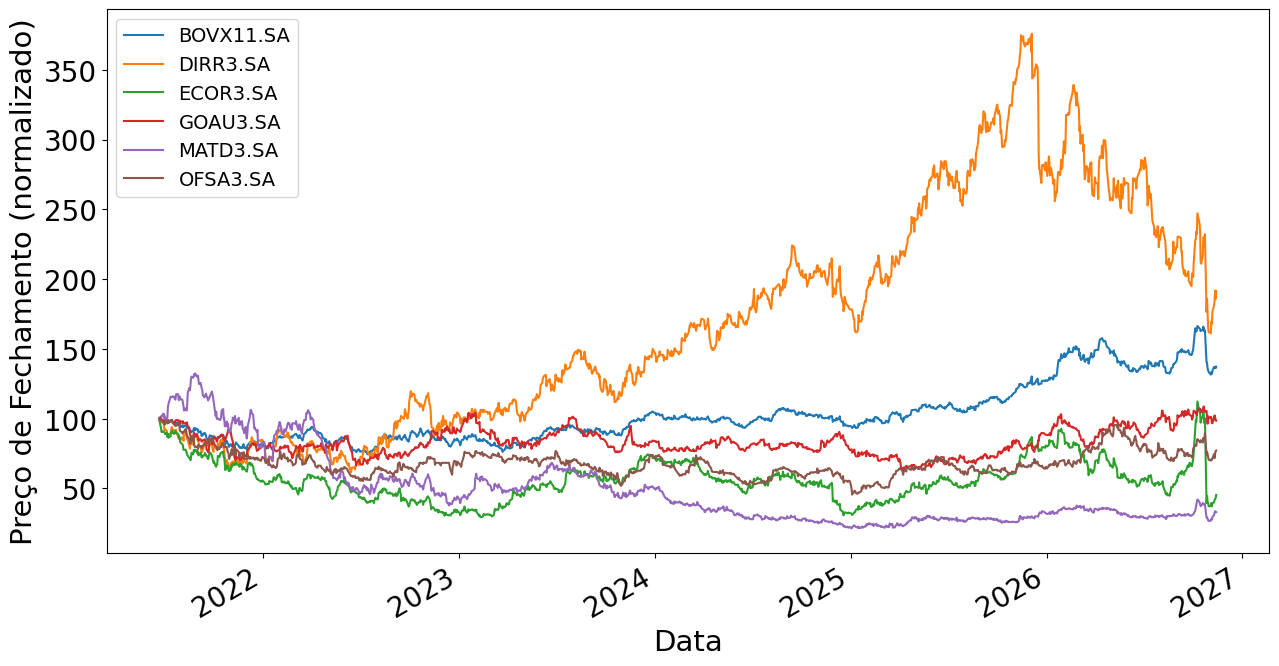

In [2]:
import modules.classic as c
import yfinance as yf

ativos       = ["MATD3.SA","DIRR3.SA","ECOR3.SA","OFSA3.SA","GOAU3.SA","BOVX11.SA"]
data_inicial = "2021-06-21" # formato: YYYY-MM-DD (Ano-Mês-Dia)
#data_final   = "2026-11-14" # Até a data atual

df  =  yf.download(ativos, start=data_inicial, auto_adjust=False, progress=False)
c.vis_preco_historico_total(df)

## Conversão de escalas

In [3]:
# ---------------------------------------------------------------------------
# Escalas de tempo
# ---------------------------------------------------------------------------
# escala -> (regra de resample do pandas, períodos por ano)
# "semestral" usa os fechamentos de jun/dez (semestres de calendário).
ESCALAS = {
    "diaria": (None, 252),
    "mensal": ("ME", 12),
    "trimestral": ("QE", 4),
    "semestral": ("QE", 2),
    "anual": ("YE", 1),
}
ROTULOS = {
    "diaria": "diário",
    "mensal": "mensal",
    "trimestral": "trimestral",
    "semestral": "semestral",
    "anual": "anual",
}

In [4]:
def _checar_escala(escala):
    if escala not in ESCALAS:
        raise ValueError(
            f"Escala '{escala}' inválida. Use uma de: {list(ESCALAS)}."
        )

def converter_taxa(taxa_anual, escala):
    """Converte uma taxa anual para a escala escolhida (juros compostos)."""
    _checar_escala(escala)
    per_ano = ESCALAS[escala][1]
    return (1 + taxa_anual) ** (1 / per_ano) - 1

## Simulação para escalas diferentes

In [6]:
port_diff_esc = c.comparar_escalas(df, retorno_alvo=0.13)

Aviso: O retorno desejado é maior que o retorno máximo simulado. Retornando o portfólio de maior retorno.
Aviso: O retorno desejado é maior que o retorno máximo simulado. Retornando o portfólio de maior retorno.
Aviso: O retorno desejado é maior que o retorno máximo simulado. Retornando o portfólio de maior retorno.
Aviso: O retorno desejado é maior que o retorno máximo simulado. Retornando o portfólio de maior retorno.


/home/labneurofisica/Documents/Projetos/Quantitative_Finance/quantum_finance/Experimentos/modules/classic.py:89: UserWarning: Escala 'anual': só 5 observações para 6 ativos. A matriz de covariância fica singular/pouco confiável.
  warnings.warn(
